# Task 3: Principal Component Analysis (PCA) from Scratch Using NumPy

**Objective:** Implement PCA using linear algebra operations in NumPy to reduce the dimensionality of a structured dataset.

**Dataset:** Iris flower dataset (150 samples, 4 numerical features, 3 species). Scikit-learn is used only to load the built-in dataset; the PCA calculations are implemented using NumPy rather than a ready-made PCA estimator.

**Method:** standardize features → compute covariance matrix → calculate eigenvalues/eigenvectors → sort principal components → project data into 2 dimensions → evaluate explained variance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data.astype(float)
y = iris.target
feature_names = iris.feature_names
species_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df["species"] = [species_names[i] for i in y]
print("Dataset shape:", X.shape)
display(df.head())

Dataset shape: (150, 4)


## 1. Standardize the features

PCA is affected by feature scale. We standardize each feature so it has mean 0 and sample standard deviation 1. This makes the analysis comparable across measurements with different ranges.

In [2]:
mean = np.mean(X, axis=0)
std = np.std(X, axis=0, ddof=1)
X_standardized = (X - mean) / std

print("Means after standardization (approximately 0):")
print(np.round(X_standardized.mean(axis=0), 6))
print("\\nSample standard deviations (approximately 1):")
print(np.round(X_standardized.std(axis=0, ddof=1), 6))

Means after standardization (approximately 0):
[-0. -0. -0. -0.]
\nSample standard deviations (approximately 1):
[1. 1. 1. 1.]


## 2. Compute the covariance matrix

The covariance matrix describes how pairs of features vary together.

In [3]:
cov_matrix = np.cov(X_standardized, rowvar=False)
print("Covariance matrix:")
print(np.round(cov_matrix, 3))

Covariance matrix:
[[ 1.    -0.118  0.872  0.818]
 [-0.118  1.    -0.428 -0.366]
 [ 0.872 -0.428  1.     0.963]
 [ 0.818 -0.366  0.963  1.   ]]


## 3. Calculate eigenvalues and eigenvectors

Eigenvectors define principal directions and eigenvalues measure the variance along those directions. `np.linalg.eigh` is suitable because the covariance matrix is symmetric.

In [4]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("Eigenvalues (descending):")
print(np.round(eigenvalues, 4))
print("\\nEigenvectors (columns are principal directions):")
print(np.round(eigenvectors, 4))

Eigenvalues (descending):
[2.9185 0.914  0.1468 0.0207]
\nEigenvectors (columns are principal directions):
[[-0.5211  0.3774  0.7196  0.2613]
 [ 0.2693  0.9233 -0.2444 -0.1235]
 [-0.5804  0.0245 -0.1421 -0.8014]
 [-0.5649  0.0669 -0.6343  0.5236]]


## 4. Select principal components and explained variance

The first two eigenvectors correspond to the two largest eigenvalues. Explained variance ratio measures the fraction of total variance represented by each component.

In [5]:
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(explained_variance_ratio)
variance_table = pd.DataFrame({
    "Principal Component": [f"PC{i+1}" for i in range(len(eigenvalues))],
    "Eigenvalue": eigenvalues,
    "Explained Variance Ratio": explained_variance_ratio,
    "Cumulative Explained Variance": cumulative_variance
})
display(variance_table.round(4))

n_components = 2
projection_matrix = eigenvectors[:, :n_components]
print("Projection matrix shape:", projection_matrix.shape)
print("Variance retained by 2 components:", round(cumulative_variance[1] * 100, 2), "%")

Projection matrix shape: (4, 2)
Variance retained by 2 components: 95.81 %


## 5. Project the data into 2 dimensions

The projection is matrix multiplication between standardized observations and the selected eigenvectors.

In [6]:
X_pca = np.dot(X_standardized, projection_matrix)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["species"] = [species_names[i] for i in y]
print("Original data shape:", X.shape)
print("Reduced data shape:", X_pca.shape)
display(pca_df.head())

Original data shape: (150, 4)
Reduced data shape: (150, 2)


## 6. Visualize the reduced dataset

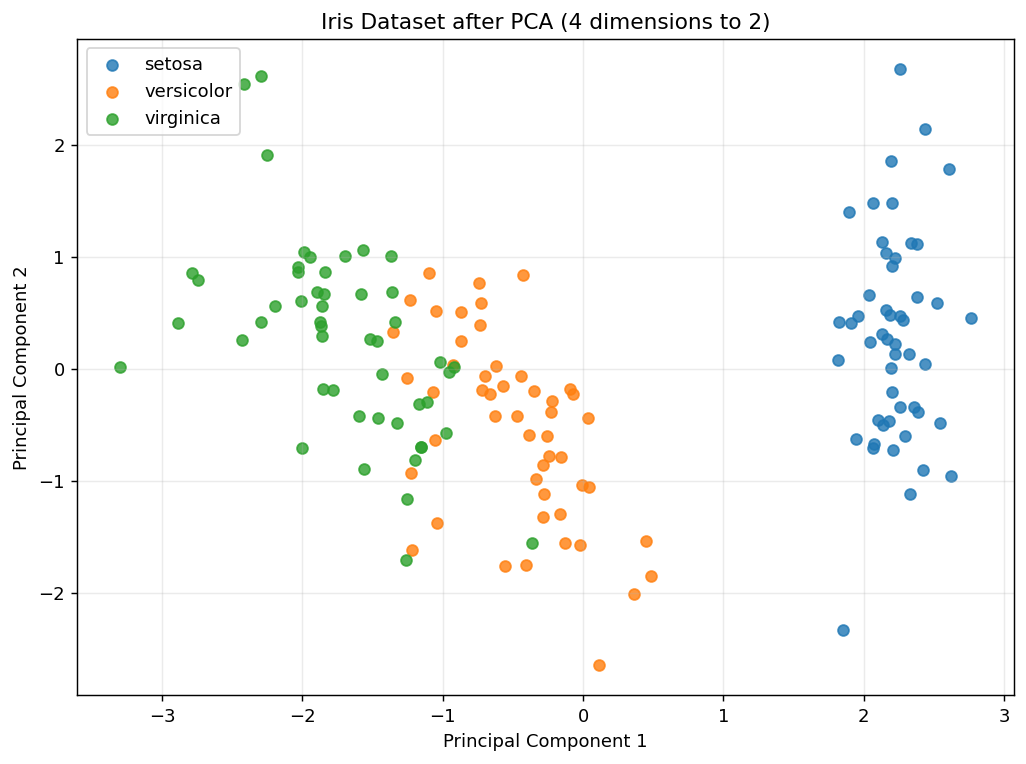

In [7]:
plt.figure(figsize=(8, 6))
for class_id, species in enumerate(species_names):
    plt.scatter(X_pca[y == class_id, 0], X_pca[y == class_id, 1], label=species, alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Dataset after PCA (4 dimensions to 2)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Plot explained variance

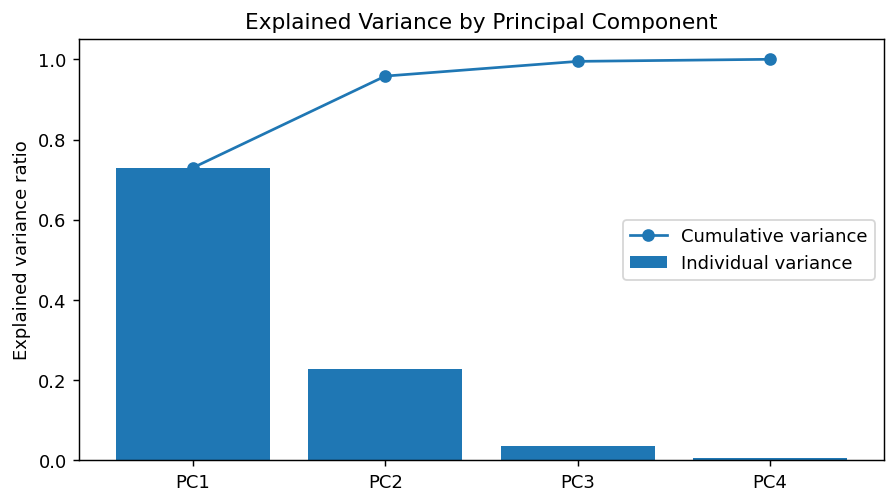

In [8]:
plt.figure(figsize=(7, 4))
labels = [f"PC{i+1}" for i in range(len(eigenvalues))]
plt.bar(labels, explained_variance_ratio, label="Individual variance")
plt.plot(labels, cumulative_variance, marker="o", label="Cumulative variance")
plt.ylabel("Explained variance ratio")
plt.title("Explained Variance by Principal Component")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Conclusion

PCA was implemented using NumPy linear algebra operations. The four standardized Iris measurements were transformed into principal component directions using eigenvalues and eigenvectors of the covariance matrix. The data was projected from four dimensions to two dimensions.

The first two principal components retain **95.81%** of the total variance in this dataset. This demonstrates how PCA reduces the number of features while preserving most of the variation in the original data.

**Important:** PCA is unsupervised. Species labels were used only to color the visualization, not to calculate the principal components. Scikit-learn was used only to load the Iris dataset; PCA itself was implemented using NumPy.